## **1.2 Mempelajari Penggunaan Driver Neo4j Python**

In [ ]:
from neo4j import GraphDatabase

URI = "neo4j://localhost:7687"
AUTH = ("neo4j", "Password")

In [2]:
def add_friend(driver, name, friend_name):
    with driver.session(database="neo4j") as session:
        session.run(
            "MERGE (a:Person {name: $name}) "
            "MERGE (friend:Person {name: $friend_name}) "
            "MERGE (a)-[:KNOWS]->(friend)",
            name=name,
            friend_name=friend_name,
        )

In [3]:

def print_friends(driver, name):
    with driver.session(database="neo4j") as session:
        result = session.run(
            "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
            "RETURN friend.name ORDER BY friend.name",
            name=name,
        )
        for record in result:
            print(record["friend.name"])

with GraphDatabase.driver(URI, auth=AUTH, ) as driver:
    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")
    print_friends(driver, "Arthur")

Guinevere
Lancelot
Merlin


### Penjelasan

Kode ini digunakan untuk menghubungkan Python dengan database Neo4j. Fungsi `add_friend()` membuat node `Person` dan relationship `KNOWS` menggunakan `MERGE`, sedangkan `print_friends()` mengambil dan menampilkan daftar teman Arthur menggunakan query Cypher `MATCH` dan `RETURN`.

**Pertanyaan Pendahuluan (Checkpoint)**

**1. Apa nama database yang digunakan pada tutorial ini?**

Database yang digunakan adalah neo4j.

**2.  Sebutkan akses lain (seperti sintaks DDL/DML Cypher) yang dapat digunakan untuk mengakses database lain dalam satu instance!**

Database lain dapat diakses menggunakan perintah Cypher seperti SHOW DATABASES, CREATE DATABASE, dan USE nama_database

**3. Apa jenis graf pertemanan yang telah dibuat di sini?**

Graf berarah (directed graph), karena relasi KNOWS dibuat dari satu orang menuju orang lain, yaitu (a)-[:KNOWS]->(friend).

## **1.3 Melakukan proses Impor Data dari RetailRocket ke Database Neo4J**

In [4]:
import os
import pandas as pd
from pathlib import Path
from neo4j import GraphDatabase
from tqdm.notebook import tqdm

In [5]:
# Lokasi dataset
csv_path = Path("data/events.csv")

# Membaca dataset
df = pd.read_csv(csv_path)

# Melihat ukuran dan isi dataset
print("Ukuran dataset:", df.shape)

print("\nNama kolom:")
print(df.columns.tolist())

print("\nLima baris pertama:")
display(df.head())

print("\nInformasi dataset:")
df.info()

Ukuran dataset: (2756101, 5)

Nama kolom:
['timestamp', 'visitorid', 'event', 'itemid', 'transactionid']

Lima baris pertama:


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN



Informasi dataset:
<class 'pandas.DataFrame'>
RangeIndex: 2756101 entries, 0 to 2756100
Data columns (total 5 columns):
 #   Column         Dtype  
---  ------         -----  
 0   timestamp      int64  
 1   visitorid      int64  
 2   event          str    
 3   itemid         int64  
 4   transactionid  float64
dtypes: float64(1), int64(3), str(1)
memory usage: 105.1 MB


In [6]:
# Melihat jumlah setiap jenis interaksi
print("Jumlah setiap jenis interaksi:")
print(df["event"].value_counts())

# Memeriksa data transactionid yang kosong
print("\nJumlah transactionid kosong:")
print(df["transactionid"].isna().sum())

# Memeriksa rentang waktu dataset
print("\nRentang timestamp:")
print("Minimum:", df["timestamp"].min())
print("Maksimum:", df["timestamp"].max())

Jumlah setiap jenis interaksi:
event
view           2664312
addtocart        69332
transaction      22457
Name: count, dtype: int64

Jumlah transactionid kosong:
2733644

Rentang timestamp:
Minimum: 1430622004384
Maksimum: 1442545187788


**Koneksi ke Neo4j**

In [ ]:
from neo4j import GraphDatabase

URI = "neo4j://localhost:7687"
AUTH = ("neo4j", "Password")

driver = GraphDatabase.driver(URI, auth=AUTH)
driver.verify_connectivity()

print("Koneksi ke Neo4j berhasil")

C:\Users\ASUS\AppData\Local\Temp\ipykernel_15512\1696485835.py:7: ExperimentalWarning: The configuration may change in the future.
  driver.verify_connectivity()


Koneksi ke Neo4j berhasil


In [8]:
def create_constraints(session):
    session.run("""
        CREATE CONSTRAINT visitor_id IF NOT EXISTS
        FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE
    """)
    session.run("""
        CREATE CONSTRAINT item_id IF NOT EXISTS
        FOR (i:Item) REQUIRE i.itemId IS UNIQUE
    """)

In [9]:
def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    WITH v, i, row
    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {
            timestamp: row.timestamp,
            transactionId: row.transactionid
        }]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)

**Impor dataset ke Neo4j**

In [10]:
import math
import pandas as pd
from tqdm.notebook import tqdm

# Pengaturan impor
batch_size = 5000
csv_file_path = Path("data/events.csv")

# Membaca dataset secara bertahap
total_rows = sum(1 for _ in open(csv_file_path)) - 1
total_chunks = math.ceil(total_rows / batch_size)

with driver.session() as session:
    create_constraints(session)

    print("Membaca file data dari:", csv_file_path)
    chunks = pd.read_csv(csv_file_path, chunksize=batch_size)

    print("Memulai proses impor data ke Neo4j...")

    for chunk in tqdm(chunks, total=total_chunks, desc="Mengimpor Batch Data"):
        # Membersihkan transactionid yang kosong
        chunk["transactionid"] = (
            chunk["transactionid"].fillna("").astype(str)
        )

        records = chunk.to_dict(orient="records")
        session.write_transaction(import_batch, records)

driver.close()
print("Proses impor selesai!")

Membaca file data dari: data\events.csv
Memulai proses impor data ke Neo4j...


Mengimpor Batch Data:   0%|          | 0/552 [00:00<?, ?it/s]

Proses impor selesai!


**Verifikasi Hasil Impor**

In [10]:
driver = GraphDatabase.driver(URI, auth=AUTH)

Untuk memeriksa jumlah node berdasarkan label, yaitu Person, Visitor, dan Item.

In [11]:
with driver.session() as session:
    result = session.run("""
        MATCH (n)
        RETURN labels(n) AS jenis_node, count(n) AS jumlah
    """)

    for record in result:
        print(record["jenis_node"], ":", record["jumlah"])

['Person'] : 4
['Visitor'] : 1407580
['Item'] : 235061


Memeriksa jumlah relationship berdasarkan jenisnya. Hasilnya menunjukkan terdapat relationship VIEWED, ADDED_TO_CART, BOUGHT, SIMILAR_TO, dan KNOWS.

In [12]:
with driver.session() as session:
    result = session.run("""
        MATCH ()-[r]->()
        RETURN type(r) AS jenis_relasi, count(r) AS jumlah
        ORDER BY jumlah DESC
    """)

    for record in result:
        print(record["jenis_relasi"], ":", record["jumlah"])

VIEWED : 2664312
ADDED_TO_CART : 69332
BOUGHT : 22457
SIMILAR_TO : 5
KNOWS : 3


Memverifikasi hubungan antara node Visitor dan Item. Hasilnya menunjukkan bahwa ketiga jenis interaksi utama, yaitu VIEWED, ADDED_TO_CART, dan BOUGHT, berhasil tersimpan di database Neo4j.

In [14]:
with driver.session() as session:
    result = session.run("""
        MATCH (v:Visitor)-[r]->(i:Item)
        RETURN type(r) AS jenis_relasi,
               count(r) AS jumlah
        ORDER BY jumlah DESC
    """)

    for record in result:
        print(record["jenis_relasi"], ":", record["jumlah"])

VIEWED : 2664312
ADDED_TO_CART : 69332
BOUGHT : 22457


## **Soal UTS**

## **2.1Wrangling dan EDA**

**1.  Tentukan 2 periode waktu sebagai filter dari data interaksi. Kombinasi periode yg dipilih per individu tidak boleh sama dalam 1 kelas.Misal: Fold training (P1) → 01/2023 - 03/2023; Fold testing (P2) 01/2024 06/2024.**

Dilakukannya menentukan periode yang akan digunakan:
- P1 (training): 3 Mei–12 Juni 2015
- P2 (testing): 13 Juni–25 Juli 2015

In [13]:
import pandas as pd
from pathlib import Path

csv_path = Path("data/events.csv")
df = pd.read_csv(csv_path)

df["datetime"] = pd.to_datetime(df["timestamp"], unit="ms")

print("Rentang tanggal dataset:")
print("Tanggal minimum:", df["datetime"].min())
print("Tanggal maksimum:", df["datetime"].max())

Rentang tanggal dataset:
Tanggal minimum: 2015-05-03 03:00:04.384000
Tanggal maksimum: 2015-09-18 02:59:47.788000


**2. Terapkan proses filter ini pada timestamp pada proses persiapan data, lalu simpan pada sebuah file .csv!**

In [14]:
# Menentukan periode training dan testing
p1_start = "2015-05-03"
p1_end = "2015-06-12"

p2_start = "2015-06-13"
p2_end = "2015-07-25"

# Memfilter data P1
p1 = df[
    (df["datetime"] >= p1_start) &
    (df["datetime"] < "2015-06-13")
].copy()

p1["period"] = "P1"

# Memfilter data P2
p2 = df[
    (df["datetime"] >= p2_start) &
    (df["datetime"] < "2015-07-26")
].copy()

p2["period"] = "P2"

# Menggabungkan kedua periode
df_filtered = pd.concat([p1, p2], ignore_index=True)

# Menyimpan hasil filter
output_path = Path("data/events_filtered.csv")
df_filtered.to_csv(output_path, index=False)

print("Jumlah data P1:", len(p1))
print("Jumlah data P2:", len(p2))
print("Total data hasil filter:", len(df_filtered))
print("File tersimpan di:", output_path)

display(df_filtered.head())

Jumlah data P1: 842524
Jumlah data P2: 910144
Total data hasil filter: 1752668
File tersimpan di: data\events_filtered.csv


,timestamp,visitorid,event,itemid,transactionid,datetime,period
0,1433221332117,257597,view,355908,NaN,2015-06-02 05:02:12.117,P1
1,1433224214164,992329,view,248676,NaN,2015-06-02 05:50:14.164,P1
2,1433221999827,111016,view,318965,NaN,2015-06-02 05:13:19.827,P1
3,1433221955914,483717,view,253185,NaN,2015-06-02 05:12:35.914,P1
4,1433221337106,951259,view,367447,NaN,2015-06-02 05:02:17.106,P1


In [15]:
print("Jumlah interaksi berdasarkan periode:")
print(df_filtered["period"].value_counts())

print("\nJenis interaksi berdasarkan periode:")
display(
    pd.crosstab(
        df_filtered["period"],
        df_filtered["event"]
    )
)

print("\nJumlah visitor unik:", df_filtered["visitorid"].nunique())
print("Jumlah item unik:", df_filtered["itemid"].nunique())

print("\nJumlah transaksi yang memiliki transactionid:")
print(df_filtered["transactionid"].notna().sum())

Jumlah interaksi berdasarkan periode:
period
P2    910144
P1    842524
Name: count, dtype: int64

Jenis interaksi berdasarkan periode:


event,addtocart,transaction,view
period,,,
P1,20221,6583,815720
P2,22989,7569,879586



Jumlah visitor unik: 890692
Jumlah item unik: 193841

Jumlah transaksi yang memiliki transactionid:
14152


**3. Lakukan query untuk mendapatkan komposisi dari subgraph yang dibuat. Uraikan jenis simpul dan jumlah
masing-masing simpul dengan Python API! Jelaskan CYPHER SQL yang digunakan!**

In [ ]:
from neo4j import GraphDatabase

URI = "neo4j://localhost:7687"
AUTH = ("neo4j", "Password")

driver = GraphDatabase.driver(URI, auth=AUTH)
driver.verify_connectivity()

print("Berhasil terhubung ke Neo4j")

C:\Users\ASUS\AppData\Local\Temp\ipykernel_15512\1013787609.py:7: ExperimentalWarning: The configuration may change in the future.
  driver.verify_connectivity()


Berhasil terhubung ke Neo4j


In [17]:
driver = GraphDatabase.driver(URI, auth=AUTH)
driver.verify_connectivity()

periods = {
    "P1": (
        int(pd.Timestamp("2015-05-03", tz="UTC").timestamp() * 1000),
        int(pd.Timestamp("2015-06-13", tz="UTC").timestamp() * 1000)
    ),
    "P2": (
        int(pd.Timestamp("2015-06-13", tz="UTC").timestamp() * 1000),
        int(pd.Timestamp("2015-07-26", tz="UTC").timestamp() * 1000)
    )
}

query = """
MATCH (v:Visitor)-[r]->(i:Item)
WHERE r.timestamp >= $start_time
  AND r.timestamp < $end_time
RETURN
    count(DISTINCT v) AS jumlah_visitor,
    count(DISTINCT i) AS jumlah_item,
    count(r) AS jumlah_interaksi,
    count(CASE WHEN type(r) = 'VIEWED' THEN 1 END) AS viewed,
    count(CASE WHEN type(r) = 'ADDED_TO_CART' THEN 1 END) AS added_to_cart,
    count(CASE WHEN type(r) = 'BOUGHT' THEN 1 END) AS bought
"""

results = []

with driver.session() as session:
    for nama_periode, (start_time, end_time) in periods.items():
        record = session.run(
            query,
            start_time=start_time,
            end_time=end_time
        ).single()

        results.append({
            "Periode": nama_periode,
            "Jumlah Visitor": record["jumlah_visitor"],
            "Jumlah Item": record["jumlah_item"],
            "Jumlah Interaksi": record["jumlah_interaksi"],
            "VIEWED": record["viewed"],
            "ADDED_TO_CART": record["added_to_cart"],
            "BOUGHT": record["bought"]
        })

df_composition = pd.DataFrame(results)
display(df_composition)

C:\Users\ASUS\AppData\Local\Temp\ipykernel_15512\4212238102.py:2: ExperimentalWarning: The configuration may change in the future.
  driver.verify_connectivity()


,Periode,Jumlah Visitor,Jumlah Item,Jumlah Interaksi,VIEWED,ADDED_TO_CART,BOUGHT
0,P1,433249,137665,842524,815720,20221,6583
1,P2,478582,145215,910144,879586,22989,7569


Berdasarkan hasil query, periode P1 memiliki 433.249 visitor, 137.665 item, dan 842.524 interaksi. Sementara itu, periode P2 memiliki 478.582 visitor, 145.215 item, dan 910.144 interaksi. Jenis interaksi yang paling banyak pada kedua periode adalah VIEWED, sedangkan BOUGHT memiliki jumlah paling sedikit. Secara keseluruhan, jumlah visitor, item, dan interaksi pada P2 lebih tinggi dibandingkan P1.

**4. Lakukan Vector Space Modelling (VSM) terhadap simpul yang diasumsikan sebagai User. Uraikan bagaimana
karakteristiknya (dimensi, shape, plot networkx, dst.)!**

In [18]:
import pandas as pd
import numpy as np
from scipy.sparse import csr_matrix

# Membaca data hasil filtering
df_filtered = pd.read_csv("data/events_filtered.csv")

# Menggunakan data P1 terlebih dahulu sebagai data training
df_p1 = df_filtered[df_filtered["period"] == "P1"].copy()

# Mengubah ID menjadi indeks matriks
user_codes, user_ids = pd.factorize(df_p1["visitorid"])
item_codes, item_ids = pd.factorize(df_p1["itemid"])

# Bobot interaksi
weights = {
    "view": 1,
    "addtocart": 2,
    "transaction": 3
}

df_p1["weight"] = df_p1["event"].map(weights)

# Membuat matriks User-Item
user_item_matrix = csr_matrix(
    (
        df_p1["weight"].to_numpy(),
        (user_codes, item_codes)
    ),
    shape=(len(user_ids), len(item_ids))
)

# Menggabungkan interaksi berulang pada pasangan User-Item
user_item_matrix.sum_duplicates()

print("Jumlah User:", len(user_ids))
print("Jumlah Item:", len(item_ids))
print("Shape matriks VSM:", user_item_matrix.shape)
print("Jumlah nilai non-zero:", user_item_matrix.nnz)
print("Total elemen matriks:", user_item_matrix.shape[0] * user_item_matrix.shape[1])

Jumlah User: 433249
Jumlah Item: 137665
Shape matriks VSM: (433249, 137665)
Jumlah nilai non-zero: 653018
Total elemen matriks: 59643223585


Jumlah node User pada proyeksi: 50
Jumlah edge User-User: 1057


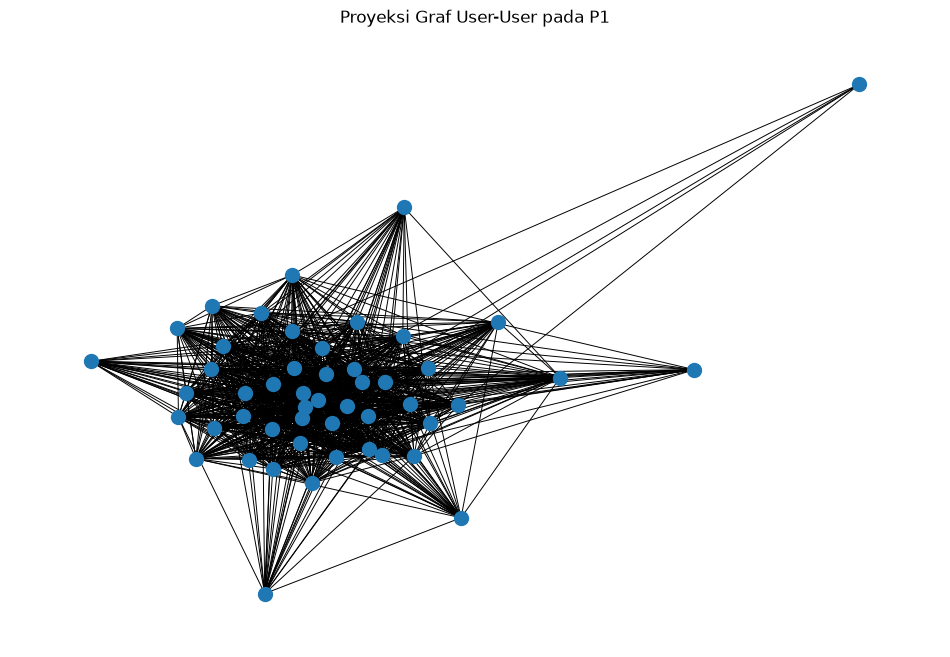

In [19]:
import networkx as nx
import matplotlib.pyplot as plt

# Menghitung aktivitas masing-masing user
user_activity = np.asarray(user_item_matrix.sum(axis=1)).ravel()

# Memilih maksimal 50 user paling aktif
top_n = min(50, len(user_ids))
top_users = np.argsort(user_activity)[-top_n:]

# Mengambil baris matriks untuk user terpilih
selected_matrix = user_item_matrix[top_users, :]

# Membuat graf bipartit User-Item
B = nx.Graph()

selected_user_labels = [str(user_ids[i]) for i in top_users]

for user in selected_user_labels:
    B.add_node(f"U_{user}", bipartite="user")

coo = selected_matrix.tocoo()

for row, col, value in zip(coo.row, coo.col, coo.data):
    user = selected_user_labels[row]
    item = str(item_ids[col])

    B.add_node(f"I_{item}", bipartite="item")
    B.add_edge(f"U_{user}", f"I_{item}", weight=float(value))

# Proyeksi ke graf User-User
user_nodes = [n for n, d in B.nodes(data=True) if d["bipartite"] == "user"]
G_user = nx.bipartite.weighted_projected_graph(B, user_nodes)

print("Jumlah node User pada proyeksi:", G_user.number_of_nodes())
print("Jumlah edge User-User:", G_user.number_of_edges())

# Visualisasi graf proyeksi
plt.figure(figsize=(12, 8))
pos = nx.spring_layout(G_user, seed=42)

nx.draw_networkx(
    G_user,
    pos,
    with_labels=False,
    node_size=100,
    width=0.7
)

plt.title("Proyeksi Graf User-User pada P1")
plt.axis("off")
plt.show()

Berdasarkan hasil pengolahan data P1, matriks VSM User memiliki 433.249 baris dan 137.665 kolom, dengan total 59.643.223.585 elemen. Namun, hanya terdapat 653.018 elemen yang bernilai non-zero. Hal ini menunjukkan bahwa matriks bersifat sparse karena sebagian besar User hanya berinteraksi dengan sebagian kecil Item.

Pada visualisasi proyeksi graf User-User, terlihat banyak hubungan yang terkumpul di bagian tengah, sementara beberapa node berada lebih jauh dari kelompok utama. Hubungan antarnode terbentuk karena adanya Item yang pernah diinteraksikan bersama. Visualisasi dibatasi pada 50 User paling aktif agar graf lebih mudah diamati.

**5. Lakukan VSM terhadap simpul yang diasumsikan sebagai Item. Uraikan bagaimana karakteristiknya (di-
mensi, shape, plot networkx, dst.)!**

In [20]:
# Membentuk matriks Item-User
item_user_matrix = user_item_matrix.T.tocsr()

print("Jumlah Item:", item_user_matrix.shape[0])
print("Jumlah User:", item_user_matrix.shape[1])
print("Shape matriks VSM Item:", item_user_matrix.shape)
print("Jumlah nilai non-zero:", item_user_matrix.nnz)
print(
    "Total elemen matriks:",
    item_user_matrix.shape[0] * item_user_matrix.shape[1]
)

Jumlah Item: 137665
Jumlah User: 433249
Shape matriks VSM Item: (137665, 433249)
Jumlah nilai non-zero: 653018
Total elemen matriks: 59643223585


Jumlah node Item pada proyeksi: 11057
Jumlah edge Item-Item: 4649558


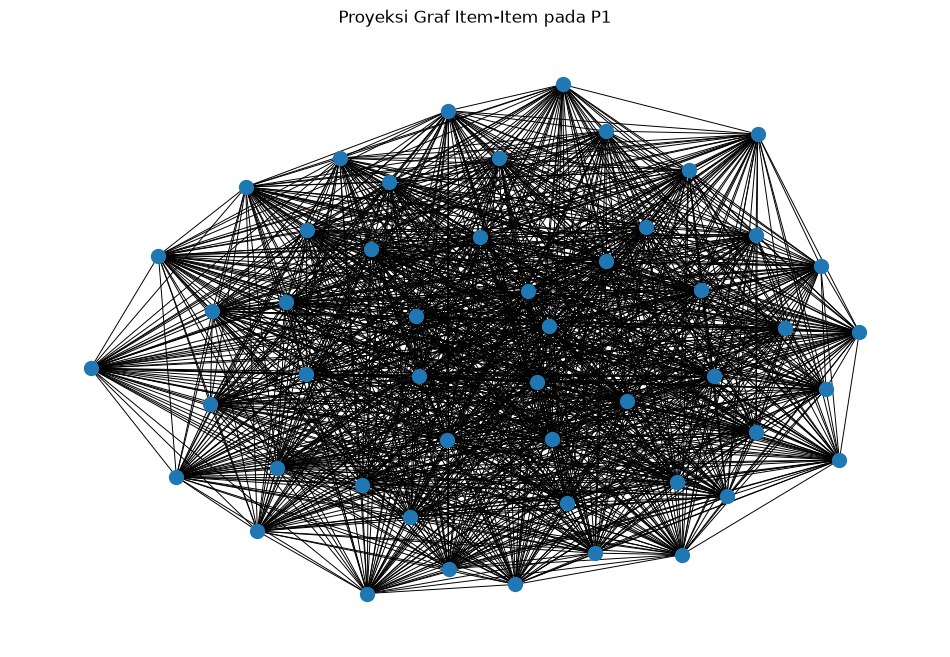

In [21]:
# Proyeksi Item-Item berdasarkan User yang sama
item_nodes = [
    n for n, d in B.nodes(data=True)
    if d["bipartite"] == "item"
]

G_item = nx.bipartite.weighted_projected_graph(B, item_nodes)

print("Jumlah node Item pada proyeksi:", G_item.number_of_nodes())
print("Jumlah edge Item-Item:", G_item.number_of_edges())

# Ambil maksimal 50 item dengan degree tertinggi
top_items = sorted(
    G_item.degree(),
    key=lambda x: x[1],
    reverse=True
)[:50]

selected_items = [node for node, degree in top_items]
G_item_sample = G_item.subgraph(selected_items).copy()

plt.figure(figsize=(12, 8))
pos = nx.spring_layout(G_item_sample, seed=42)

nx.draw_networkx(
    G_item_sample,
    pos,
    with_labels=False,
    node_size=100,
    width=0.7
)

plt.title("Proyeksi Graf Item-Item pada P1")
plt.axis("off")
plt.show()

Berdasarkan hasil pengolahan data P1, matriks VSM Item memiliki 137.665 baris dan 433.249 kolom, dengan total 59.643.223.585 elemen. Jumlah nilai non-zero sebanyak 653.018, yang menunjukkan bahwa matriks bersifat sparse karena sebagian besar Item hanya berinteraksi dengan sebagian kecil User.

Pada visualisasi proyeksi graf Item-Item, terlihat banyak hubungan antarnode yang membentuk jaringan cukup padat. Hubungan tersebut menunjukkan bahwa beberapa Item pernah diinteraksikan oleh User yang sama. Proyeksi ini dapat digunakan untuk melihat kemiripan Item dan menjadi dasar dalam sistem rekomendasi produk.

**6. Berdasarkan eksplorasi no. 4 dan 5, uraikan proyeksi manakah yang lebih baik (efektif/efisien)!**

Berdasarkan hasil VSM, matriks User-Item memiliki ukuran yang sama dengan matriks Item-User yang ditransposisikan, yaitu 433.249 × 137.665 dan 137.665 × 433.249. Keduanya memiliki 653.018 nilai non-zero, sehingga matriks bersifat sparse.

Menurut saya, proyeksi Item-Item lebih sesuai untuk sistem rekomendasi produk karena dapat menghubungkan produk berdasarkan kesamaan User yang pernah berinteraksi dengannya. Dengan begitu, produk yang memiliki pola interaksi serupa dapat digunakan untuk memberikan rekomendasi kepada pengguna.

Sementara itu, proyeksi User-User lebih berfokus pada kemiripan perilaku antar pengguna. Untuk tujuan merekomendasikan produk, proyeksi Item-Item lebih relevan. Namun, dari segi efisiensi komputasi, keduanya tetap perlu mempertimbangkan jumlah node dan edge yang terbentuk karena kedua graf dapat menjadi sangat padat.

**7. Berdasarkan analisis no. 6, lakukan perhitungan similarity pada hasil graf yg terproyeksi dengan menggu-
nakan Python**

**7(a). Tuliskan CYPHER SQL untuk mendapatkan 5 records dengan similarity tertinggi (Anda tentukan sendiri
record acuannya)!**

In [22]:
from sklearn.metrics.pairwise import cosine_similarity
import pandas as pd
import numpy as np

# Menentukan item acuan berdasarkan total bobot interaksi tertinggi
item_activity = np.asarray(item_user_matrix.sum(axis=1)).ravel()
anchor_idx = int(np.argmax(item_activity))
anchor_item = int(item_ids[anchor_idx])

# Menghitung cosine similarity item acuan dengan seluruh item
similarity_scores = cosine_similarity(
    item_user_matrix[anchor_idx],
    item_user_matrix
).ravel()

# Mengurutkan similarity tertinggi, tanpa item acuan itu sendiri
similarity_scores[anchor_idx] = -1

top_indices = np.argsort(similarity_scores)[::-1][:5]

similarity_results = pd.DataFrame({
    "Anchor Item": anchor_item,
    "Similar Item": [int(item_ids[i]) for i in top_indices],
    "Similarity": [float(similarity_scores[i]) for i in top_indices]
})

print("Item acuan:", anchor_item)
print("5 item dengan similarity tertinggi:")
display(similarity_results)

Item acuan: 369447
5 item dengan similarity tertinggi:


,Anchor Item,Similar Item,Similarity
0,369447,274435,0.499174
1,369447,356129,0.449678
2,369447,224582,0.383356
3,369447,219687,0.364398
4,369447,379935,0.332846


**7(b). Tuliskan kembali nilai similarity-similarity tersebut pada graf yang telah ada! Perlihatkan hasil query-
nya!**

In [24]:
# Mengubah hasil similarity menjadi list of dictionaries
similarity_records = similarity_results.to_dict(orient="records")

query_save_similarity = """
UNWIND $rows AS row
MATCH (a:Item {itemId: row.`Anchor Item`})
MATCH (b:Item {itemId: row.`Similar Item`})
MERGE (a)-[r:SIMILAR_TO]->(b)
SET r.similarity = row.Similarity,
    r.period = 'P1'
RETURN
    a.itemId AS anchor_item,
    b.itemId AS similar_item,
    r.similarity AS similarity,
    r.period AS period
ORDER BY similarity DESC
"""

with driver.session() as session:
    saved_results = session.run(
        query_save_similarity,
        rows=similarity_records
    ).data()

display(pd.DataFrame(saved_results))

,anchor_item,similar_item,similarity,period
0,369447,274435,0.499174,P1
1,369447,356129,0.449678,P1
2,369447,224582,0.383356,P1
3,369447,219687,0.364398,P1
4,369447,379935,0.332846,P1


In [25]:
query_check_similarity = """
MATCH (a:Item)-[r:SIMILAR_TO]->(b:Item)
WHERE r.period = 'P1'
RETURN
    a.itemId AS anchor_item,
    b.itemId AS similar_item,
    r.similarity AS similarity
ORDER BY similarity DESC
LIMIT 5
"""

with driver.session() as session:
    check_results = session.run(query_check_similarity).data()

display(pd.DataFrame(check_results))

,anchor_item,similar_item,similarity
0,369447,274435,0.499174
1,369447,356129,0.449678
2,369447,224582,0.383356
3,369447,219687,0.364398
4,369447,379935,0.332846


Cosine Similarity digunakan untuk mengukur kemiripan pola interaksi antar-Item berdasarkan vektor User. Nilai similarity yang semakin mendekati 1 menunjukkan pola interaksi yang semakin mirip. Lima Item dengan nilai similarity tertinggi terhadap Item acuan dipilih, kemudian disimpan ke Neo4j menggunakan relationship `SIMILAR_TO` dengan properti `similarity` dan `period`.

Item acuan dipilih berdasarkan total bobot interaksi tertinggi agar pemilihannya dapat direproduksi. Hasil query Neo4j digunakan untuk memastikan nilai similarity berhasil disimpan pada graf.

**8. Tuliskan CYPHER SQL dan tunjukkan hasil graf-nya untuk memperlihatkan kondisi: sebelum dan sesudah
perhitungan similarity!**

**Sebelum Similarity**

In [26]:
query_after = """
MATCH ()-[r]->()
RETURN type(r) AS jenis_relationship, count(r) AS jumlah
ORDER BY jenis_relationship
"""

with driver.session() as session:
    after_results = session.run(query_after).data()

display(pd.DataFrame(after_results))

,jenis_relationship,jumlah
0,ADDED_TO_CART,69332
1,BOUGHT,22457
2,KNOWS,3
3,SIMILAR_TO,5
4,VIEWED,2664312


**Sesudah Similarity**

In [27]:
query_after = """
MATCH ()-[r]->()
RETURN type(r) AS jenis_relationship, count(r) AS jumlah
ORDER BY jenis_relationship
"""

with driver.session() as session:
    after_results = session.run(query_after).data()

display(pd.DataFrame(after_results))

,jenis_relationship,jumlah
0,ADDED_TO_CART,69332
1,BOUGHT,22457
2,KNOWS,3
3,SIMILAR_TO,5
4,VIEWED,2664312


**Melihat hubungan similarity pada graf**

In [28]:
query_graph = """
MATCH (a:Item)-[r:SIMILAR_TO]->(b:Item)
WHERE r.period = 'P1'
RETURN a, r, b
ORDER BY r.similarity DESC
LIMIT 5
"""

with driver.session() as session:
    graph_results = session.run(query_graph).data()

print("Jumlah hubungan similarity yang ditemukan:", len(graph_results))

Jumlah hubungan similarity yang ditemukan: 5


Analisis Relationship dan Similarity Graph

Query pertama digunakan untuk menghitung jumlah setiap jenis relationship yang tersimpan di Neo4j. Hasilnya menunjukkan bahwa VIEWED merupakan relationship terbanyak dengan 2.664.312 hubungan, diikuti ADDED_TO_CART sebanyak 69.332 dan BOUGHT sebanyak 22.457. Selain itu, terdapat 5 relationship SIMILAR_TO dan 3 relationship KNOWS.

Query kedua mengambil hubungan antar-Item dengan jenis relationship SIMILAR_TO pada periode P1, kemudian mengurutkannya berdasarkan nilai similarity dari yang tertinggi. Hasilnya ditemukan 5 hubungan similarity yang dapat digunakan untuk melihat kemiripan antar-item.

## **2.2 Analysis**

**1. Pilih seorang user secara acak (tentukan proses acak-nya, dan harus bisa di-reproduksi), lalu
(a) tuliskan skrip Python dalam merekomendasikan KNN-nya!
(b) berikan 3 item yang diiklankan untuk k = 5 pada penentuan KNN nya!**

In [52]:
import pandas as pd

# Baca dataset yang sudah difilter
df_filtered = pd.read_csv("data/events_filtered.csv")

# Pisahkan periode
p1 = df_filtered[df_filtered["period"] == "P1"].copy()
p2 = df_filtered[df_filtered["period"] == "P2"].copy()

# Simpan supaya sesuai dengan kode KNN Umi
p1.to_csv("data/events_P1.csv", index=False)
p2.to_csv("data/events_P2.csv", index=False)

print("Jumlah data P1:", len(p1))
print("Jumlah data P2:", len(p2))
print("File berhasil dibuat.")

Jumlah data P1: 842524
Jumlah data P2: 910144
File berhasil dibuat.


**Buat Matriks Training**

In [53]:

import pandas as pd
import numpy as np
from scipy.sparse import csr_matrix
from sklearn.preprocessing import normalize

p1 = pd.read_csv("data/events_P1.csv")
p2 = pd.read_csv("data/events_P2.csv")

train_interactions = p1[["visitorid", "itemid"]].drop_duplicates()

user_ids = train_interactions["visitorid"].unique()
item_ids = train_interactions["itemid"].unique()

user_index = {u: i for i, u in enumerate(user_ids)}
item_index = {item: i for i, item in enumerate(item_ids)}

rows = train_interactions["visitorid"].map(user_index).to_numpy()
cols = train_interactions["itemid"].map(item_index).to_numpy()

user_item_train = csr_matrix(
    (np.ones(len(rows)), (rows, cols)),
    shape=(len(user_ids), len(item_ids))
)

# Normalisasi untuk menghitung cosine similarity
normalized_train = normalize(user_item_train, norm="l2", axis=1)

print("Shape matriks:", user_item_train.shape)
print("Jumlah user:", len(user_ids))
print("Jumlah item:", len(item_ids))
print("Jumlah interaksi unik:", user_item_train.nnz)


Shape matriks: (433249, 137665)
Jumlah user: 433249
Jumlah item: 137665
Jumlah interaksi unik: 653018


**KNN**

In [54]:
seed = 42
rng = np.random.default_rng(seed)

users_test = set(p2["visitorid"].unique())

eligible_users = np.array([
    u for u in user_ids
    if u in users_test and user_item_train[user_index[u]].nnz >= 5
])

shuffled_users = rng.permutation(eligible_users)

target_user = None
recommendations = None
neighbors = None

for user in shuffled_users[:100]:
    target_idx = user_index[user]

    similarities = (
        normalized_train @ normalized_train[target_idx].T
    ).toarray().ravel()

    similarities[target_idx] = -1

    neighbor_indices = np.argsort(similarities)[::-1]
    neighbor_indices = [
        i for i in neighbor_indices if similarities[i] > 0
    ][:5]

    if len(neighbor_indices) < 5:
        continue

    neighbor_similarities = similarities[neighbor_indices]

    scores = np.asarray(
        user_item_train[neighbor_indices].T
        @ neighbor_similarities
    ).ravel()

    seen_items = set(user_item_train[target_idx].indices)
    scores[list(seen_items)] = 0

    top_indices = [
        i for i in np.argsort(-scores, kind="stable")
        if scores[i] > 0
    ][:5]

    if len(top_indices) >= 3:
        target_user = int(user)
        recommendations = pd.DataFrame({
            "itemid": item_ids[top_indices],
            "score": scores[top_indices]
        })
        neighbors = pd.DataFrame({
            "visitorid": user_ids[neighbor_indices],
            "similarity": similarities[neighbor_indices]
        })
        break

if target_user is None:
    print("Belum ditemukan user yang memenuhi kriteria dari 100 kandidat.")
else:
    print("Seed:", seed)
    print("User target:", target_user)
    print("\nTetangga KNN:")
    display(neighbors)
    print("\nRekomendasi item:")
    display(recommendations.head(5))


Seed: 42
User target: 589910

Tetangga KNN:


,visitorid,similarity
0,1116244,0.534522
1,767860,0.500000
2,1080700,0.500000
3,528435,0.500000
4,1157246,0.500000



Rekomendasi item:


,itemid,score
0,457231,0.534522
1,346268,0.534522
2,216862,0.534522


**Melihat Rekomendasi Item**

**2. Berdasarkan hasil rekomendasi Anda no. 1b Analytics, hitunglah:
(a) Hit@5
(b) NDCG@5**

In [55]:
target_user = 589910

relevant_items = set(
    p2.loc[
        p2["visitorid"] == target_user,
        "itemid"
    ].unique()
)

recommended_items = recommendations["itemid"].tolist()

print("User target:", target_user)
print("Item relevan P2:", relevant_items)
print("Rekomendasi:", recommended_items)
print("Jumlah item relevan:", len(relevant_items))

User target: 589910
Item relevan P2: {np.int64(269100), np.int64(67453)}
Rekomendasi: [457231, 346268, 216862]
Jumlah item relevan: 2


In [57]:

import numpy as np

k = 5
top_k = recommended_items[:k]

# Relevansi tiap item rekomendasi
hits = [
    1 if item in relevant_items else 0
    for item in top_k
]

# Hit@5
hit_at_5 = int(any(hits))

# DCG@5
dcg = sum(
    rel / np.log2(rank + 1)
    for rank, rel in enumerate(hits, start=1)
)

# IDCG@5
ideal_hits = min(len(relevant_items), k)
idcg = sum(
    1 / np.log2(rank + 1)
    for rank in range(1, ideal_hits + 1)
)

# NDCG@5
ndcg_at_5 = dcg / idcg if idcg > 0 else 0

print("Hit@5 :", hit_at_5)
print("NDCG@5:", round(ndcg_at_5, 4))


Hit@5 : 0
NDCG@5: 0.0


Berdasarkan pengujian pada user 589910, model KNN menghasilkan tiga rekomendasi, yaitu item 457231, 346268, dan 216862. Namun, tidak ada item yang sesuai dengan dua item relevan pada P2, yaitu 269100 dan 67453. Oleh karena itu, diperoleh nilai Hit@5 = 0 dan NDCG@5 = 0,0

In [58]:
driver.close()